In [1]:
from pathlib import Path
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('KERAS_HOME', str(Path.cwd() / '.keras'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from IPython.display import display


2026-10-26 23:44:45.322956: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793038485.384373   53612 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793038485.402696   53612 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793038485.443861   53612 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793038485.443917   53612 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793038485.443922   53612 computation_placer.cc:177] computation placer alr

In [2]:
SEED = 42
keras.utils.set_random_seed(SEED)
QUICK_RUN = False
print('TensorFlow:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))

EPOCHS = 1 if QUICK_RUN else 10
TRAIN_POOL_SIZE = 3000 if QUICK_RUN else 30000
TEST_SIZE = 300 if QUICK_RUN else 2000
LATENT_DIM = 32
NOISE_FACTOR = 0.4
BATCH_SIZE = 128
OUTPUT_DIR = Path('outputs/exp06')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


TensorFlow: 2.19.1
GPUs: []


E0000 00:00:1793038494.036333   53612 cuda_executor.cc:1228] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793038494.044427   53612 gpu_device.cc:2341] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [3]:
def early_stopping(patience=5):
    return keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=patience,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1,
    )


In [4]:
(x_pool, y_pool), (x_test, y_test) = keras.datasets.mnist.load_data()
x_pool, _, y_pool, _ = train_test_split(
    x_pool,
    y_pool,
    train_size=TRAIN_POOL_SIZE,
    stratify=y_pool,
    random_state=SEED,
)
x_test, _, y_test, _ = train_test_split(
    x_test,
    y_test,
    train_size=TEST_SIZE,
    stratify=y_test,
    random_state=SEED,
)
x_train, x_val = train_test_split(
    x_pool,
    test_size=0.1,
    stratify=y_pool,
    random_state=SEED,
)
x_train = x_train.astype('float32')[..., None] / 255.0
x_val = x_val.astype('float32')[..., None] / 255.0
x_test = x_test.astype('float32')[..., None] / 255.0
rng = np.random.default_rng(SEED)


In [5]:
def add_noise(images):
    noise = rng.normal(0, NOISE_FACTOR, size=images.shape).astype('float32')
    return np.clip(images + noise, 0, 1).astype('float32')


In [6]:
noisy_train, noisy_val, noisy_test = [
    add_noise(images)
    for images in (x_train, x_val, x_test)
]
print('Train:', x_train.shape, 'Validation:', x_val.shape, 'Test:', x_test.shape)
print('Pixel range:', x_train.min(), 'to', x_train.max())


Train: (27000, 28, 28, 1) Validation: (3000, 28, 28, 1) Test: (2000, 28, 28, 1)
Pixel range: 0.0 to 1.0


In [7]:
def build_dense(name):
    inputs = keras.Input((28, 28, 1))
    flattened = layers.Flatten()(inputs)
    code = layers.Dense(LATENT_DIM, activation='relu', name='latent')(flattened)
    decoded = layers.Dense(784, activation='sigmoid')(code)
    outputs = layers.Reshape((28, 28, 1))(decoded)
    return (
        keras.Model(inputs, outputs, name=name),
        keras.Model(inputs, code, name=name + '_encoder'),
    )


In [8]:
def build_convolutional():
    inputs = keras.Input((28, 28, 1))
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(16, 3, activation='relu', padding='same')(x)
    code = layers.MaxPooling2D(2, padding='same', name='latent')(x)
    x = layers.Conv2D(16, 3, activation='relu', padding='same')(code)
    x = layers.UpSampling2D(2)(x)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    outputs = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
    return (
        keras.Model(inputs, outputs, name='conv_denoising'),
        keras.Model(inputs, code, name='conv_encoder'),
    )


In [9]:
reconstruction_model, reconstruction_encoder = build_dense('dense_reconstruction')
dense_denoising_model, dense_encoder = build_dense('dense_denoising')
conv_model, conv_encoder = build_convolutional()
experiments = {
    'Dense reconstruction': (
        reconstruction_model,
        reconstruction_encoder,
        x_train,
        x_val,
    ),
    'Dense denoising': (dense_denoising_model, dense_encoder, noisy_train, noisy_val),
    'Convolutional denoising': (conv_model, conv_encoder, noisy_train, noisy_val),
}
for name, (model, encoder, _, _) in experiments.items():
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=[keras.metrics.MeanSquaredError(name='mse')],
    )
    print(name, '| latent shape:', encoder.output_shape)
    model.summary()


Dense reconstruction | latent shape: (None, 32)


Model: "dense_reconstruction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 784)            │        25,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,992 (199.19 KB)

 Trainable params: 50,992 (199.19 KB)

...

Model: "conv_denoising"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (MaxPooling2D)           │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 16)       │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,193 (47.63 KB)

 Trainable params: 12,193 (47.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
211/211 - 9s - 41ms/step - loss: 0.2901 - mse: 0.0740 - val_loss: 0.2079 - val_mse: 0.0465
Epoch 2/10
211/211 - 5s - 23ms/step - loss: 0.1827 - mse: 0.0384 - val_loss: 0.1666 - val_mse: 0.0331
Epoch 3/10
211/211 - 5s - 23ms/step - loss: 0.1552 - mse: 0.0295 - val_loss: 0.1468 - val_mse: 0.0266
Epoch 4/10
211/211 - 5s - 23ms/step - loss: 0.1389 - mse: 0.0242 - val_loss: 0.1337 - val_mse: 0.0224
Epoch 5/10
211/211 - 4s - 19ms/step - loss: 0.1279 - mse: 0.0207 - val_loss: 0.1244 - val_mse: 0.0194
Epoch 6/10
211/211 - 4s - 21ms/step - loss: 0.1196 - mse: 0.0181 - val_loss: 0.1173 - val_mse: 0.0172
Epoch 7/10
211/211 - 5s - 24ms/step - loss: 0.1134 - mse: 0.0161 - val_loss: 0.1120 - val_mse: 0.0155
Epoch 8/10
211/211 - 6s - 26ms/step - loss: 0.1088 - mse: 0.0147 - val_loss: 0.1080 - val_mse: 0.0143
Epoch 9/10
211/211 - 5s - 25ms/step - loss: 0.1054 - mse: 0.0136 - val_loss: 0.1050 - val_mse: 0.0134
Epoch 10/10
211/211 - 5s - 26ms/step - loss: 0.1027 - mse: 0.0128 - val_loss: 0.10

2026-10-26 23:47:03.431455: E tensorflow/core/util/util.cc:131] oneDNN supports DT_INT32 only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


211/211 - 41s - 193ms/step - loss: 0.2358 - mse: 0.0565 - val_loss: 0.1309 - val_mse: 0.0226
Epoch 2/10
211/211 - 32s - 151ms/step - loss: 0.1190 - mse: 0.0186 - val_loss: 0.1123 - val_mse: 0.0163
Epoch 3/10
211/211 - 32s - 153ms/step - loss: 0.1087 - mse: 0.0152 - val_loss: 0.1070 - val_mse: 0.0146
Epoch 4/10
211/211 - 29s - 138ms/step - loss: 0.1042 - mse: 0.0137 - val_loss: 0.1031 - val_mse: 0.0133
Epoch 5/10
211/211 - 22s - 106ms/step - loss: 0.1012 - mse: 0.0127 - val_loss: 0.1003 - val_mse: 0.0123
Epoch 6/10
211/211 - 22s - 106ms/step - loss: 0.0991 - mse: 0.0120 - val_loss: 0.0986 - val_mse: 0.0118
Epoch 7/10
211/211 - 22s - 105ms/step - loss: 0.0977 - mse: 0.0115 - val_loss: 0.0975 - val_mse: 0.0114
Epoch 8/10
211/211 - 22s - 104ms/step - loss: 0.0967 - mse: 0.0112 - val_loss: 0.0968 - val_mse: 0.0111
Epoch 9/10
211/211 - 22s - 106ms/step - loss: 0.0959 - mse: 0.0110 - val_loss: 0.0962 - val_mse: 0.0109
Epoch 10/10
211/211 - 21s - 100ms/step - loss: 0.0953 - mse: 0.0107 - val_l

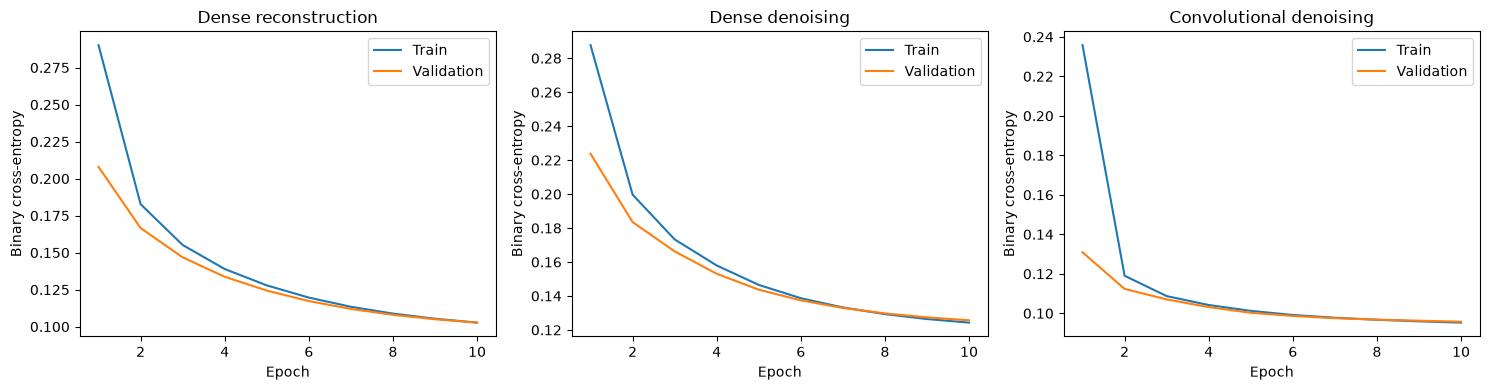

In [10]:
histories = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (model, encoder, inputs, val_inputs)) in zip(axes, experiments.items()):
    history = model.fit(
        inputs,
        x_train,
        validation_data=(val_inputs, x_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=2,
        callbacks=[early_stopping(patience=2)],
    )
    histories[name] = history
    epochs = np.arange(1, len(history.history['loss']) + 1)
    ax.plot(epochs, history.history['loss'], label='Train')
    ax.plot(epochs, history.history['val_loss'], label='Validation')
    ax.set(title=name, xlabel='Epoch', ylabel='Binary cross-entropy')
    ax.legend()
    model.save(OUTPUT_DIR / f'{model.name}.keras')
    encoder.save(OUTPUT_DIR / f'{encoder.name}.keras')
    pd.DataFrame(history.history).to_csv(
        OUTPUT_DIR / f'{model.name}_history.csv',
        index=False,
    )

fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'training_curves.png', dpi=150)
plt.show()


In [11]:
def reconstruction_metrics(reference, estimate):
    per_image_mse = np.mean((reference - estimate) ** 2, axis=(1, 2, 3))
    psnr = 10 * np.log10(1.0 / np.maximum(per_image_mse, 1e-12))
    return {'MSE': float(per_image_mse.mean()), 'Mean PSNR (dB)': float(psnr.mean())}


In [12]:
outputs = {}
rows = [{'Model': 'Noisy input', **reconstruction_metrics(x_test, noisy_test)}]
for name, (model, _, _, _) in experiments.items():
    test_inputs = x_test if name == 'Dense reconstruction' else noisy_test
    reconstructed = model.predict(test_inputs, verbose=0)
    assert reconstructed.shape == x_test.shape
    assert np.isfinite(reconstructed).all()
    assert reconstructed.min() >= 0 and reconstructed.max() <= 1
    outputs[name] = reconstructed
    rows.append({'Model': name, **reconstruction_metrics(x_test, reconstructed)})
comparison = pd.DataFrame(rows).set_index('Model')
comparison.to_csv(OUTPUT_DIR / 'reconstruction_metrics.csv')
display(comparison.round(5))
for name in ('Dense denoising', 'Convolutional denoising'):
    gain = (
        (
            (
                comparison.loc[name, 'Mean PSNR (dB)']
                - comparison.loc['Noisy input', 'Mean PSNR (dB)']
            )
        )
    )
    print(f'{name}: PSNR change {gain:+.2f} dB')
latent = dense_encoder.predict(noisy_test[:8], verbose=0)
print('Dense latent vectors:', latent.shape, '| compression:', 784 / LATENT_DIM)
np.save(OUTPUT_DIR / 'dense_latent_vectors.npy', latent)


,MSE,Mean PSNR (dB)
Model,,
Noisy input,0.07972,10.99579
Dense reconstruction,0.01198,19.85991
Dense denoising,0.01915,17.55512
Convolutional denoising,0.01040,20.17548


Dense denoising: PSNR change +6.56 dB
Convolutional denoising: PSNR change +9.18 dB
Dense latent vectors: (8, 32) | compression: 24.5


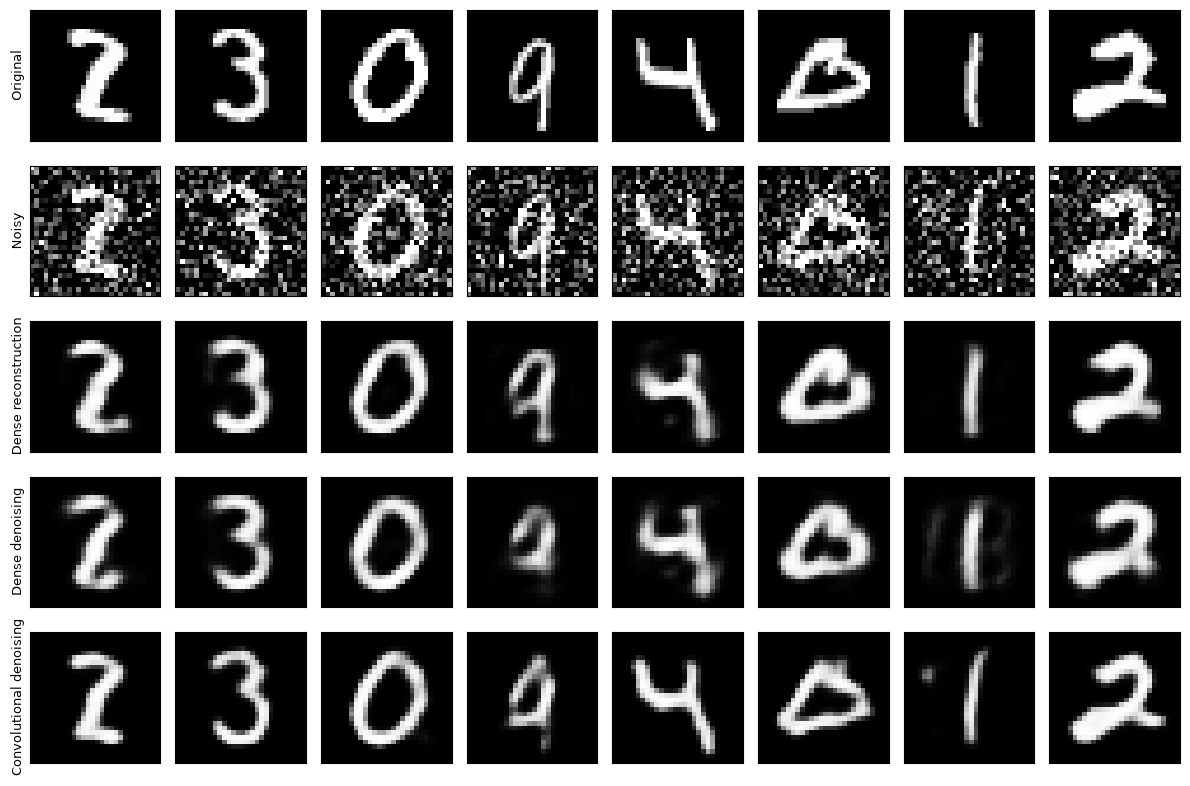

In [13]:
image_rows = {
    'Original': x_test,
    'Noisy': noisy_test,
    **outputs,
}
n = min(8, len(x_test))
fig, axes = plt.subplots(len(image_rows), n, figsize=(12, 8))
for row, (label, images) in enumerate(image_rows.items()):
    for col in range(n):
        axes[row, col].imshow(images[col, ..., 0], cmap='gray', vmin=0, vmax=1)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        if col == 0:
            axes[row, col].set_ylabel(label, fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'reconstruction_comparison.png', dpi=150)
plt.show()
